# Exploratory Data Analysis - Stress Threshold

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [2]:
df = pd.read_csv('../../feature_engineering/data/daily_features_all.csv', parse_dates=['date'])
print(f'Shape: {df.shape}')
df.head(3)

Shape: (2506, 38)


,whale_id,protocol,date,collateral_token,borrow_token,collateral_balance,borrow_balance,collateral_price,borrow_price,collateral_balance_usd,...,debt_USDe,ybt_apy,borrow_rate,carry_spread,carry_spread_levered,coll_sUSDS,coll_syrupUSDC,debt_DAI,debt_PYUSD,debt_USDtb
0,W-1,morpho,2026-02-03,sUSDe,USDtb,2.378580e+06,2.625748e+06,1.217555,0.998979,2.896050e+06,...,0,4.56949,2.574266,1.995224,21.167055,0,0,0,0,1
1,W-1,morpho,2026-02-04,sUSDe,USDtb,4.473489e+06,4.938732e+06,1.218000,0.998330,5.448708e+06,...,0,4.57329,2.747411,1.825879,19.197645,0,0,0,0,1
2,W-1,morpho,2026-02-05,sUSDe,USDtb,4.473489e+06,4.938732e+06,1.215483,0.998330,5.437451e+06,...,0,4.61732,1.086787,3.530533,37.866607,0,0,0,0,1


In [3]:
print('Whales:', df['whale_id'].unique())
print('Date range:', df['date'].min(), 'to', df['date'].max())
print('\nRows per whale:')
whale_order = sorted(df['whale_id'].unique(), key=lambda x: int(x.split('-')[1]))
print('Whales sorted:', whale_order)

Whales: <StringArray>
[ 'W-1', 'W-10', 'W-11', 'W-12', 'W-13', 'W-14', 'W-15', 'W-16', 'W-17',
 'W-18', 'W-19',  'W-2', 'W-20', 'W-21', 'W-22', 'W-23',  'W-3',  'W-4',
  'W-5',  'W-6',  'W-7',  'W-8',  'W-9']
Length: 23, dtype: str
Date range: 2024-03-29 00:00:00 to 2026-06-27 00:00:00

Rows per whale:
Whales sorted: ['W-1', 'W-2', 'W-3', 'W-4', 'W-5', 'W-6', 'W-7', 'W-8', 'W-9', 'W-10', 'W-11', 'W-12', 'W-13', 'W-14', 'W-15', 'W-16', 'W-17', 'W-18', 'W-19', 'W-20', 'W-21', 'W-22', 'W-23']


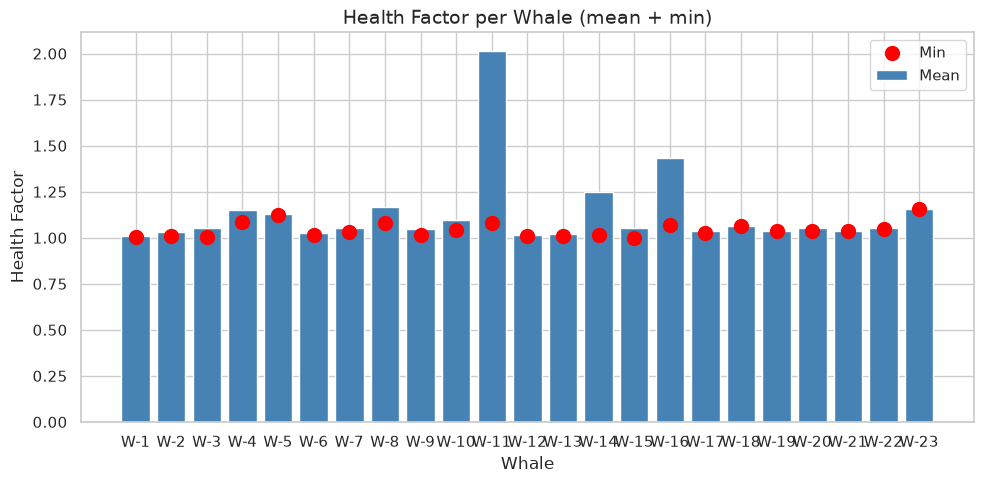

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

summary = df.groupby('whale_id')['health_factor'].agg(['mean', 'min'])

# Reorder summary using the same number based sort as before
whale_order = sorted(summary.index, key=lambda x: int(x.split('-')[1]))
summary = summary.reindex(whale_order)

ax.bar(summary.index, summary['mean'], color='steelblue', label='Mean')
ax.scatter(summary.index, summary['min'], color='red', zorder=5, label='Min', s=100)
ax.set_title('Health Factor per Whale (mean + min)', fontsize=14)
ax.set_xlabel('Whale')
ax.set_ylabel('Health Factor')
ax.legend()
plt.tight_layout()
plt.show()

**Health Factor per Whale (mean + min)**

Each bar shows the average health factor for a whale over the full sample period. The red dot marks the lowest recorded value, the closest that whale ever got to liquidation.

Most whales cluster tightly, with mean health factor between about 1.0 and 1.1, and minimums close to 1.0. A few names stand out:

- **W-11** is by far the biggest outlier. Its mean health factor is about 2.0, roughly double the rest of the group, even though its minimum sits at a normal level. This points to a whale that mostly holds a very safe position, but has had at least one sharp dip.
- **W-16** and **W-14** also run noticeably higher than average, with means around 1.4 and 1.25.
- **W-1**, **W-12**, and **W-13** sit at the risky end, with both mean and minimum close to 1.0, meaning little to no buffer above liquidation.

Overall, the group is dominated by a tight cluster of moderate risk whales, with a small number of conservative outliers (led by W-11) and a handful of chronically high risk ones (W-1, W-12, W-13).

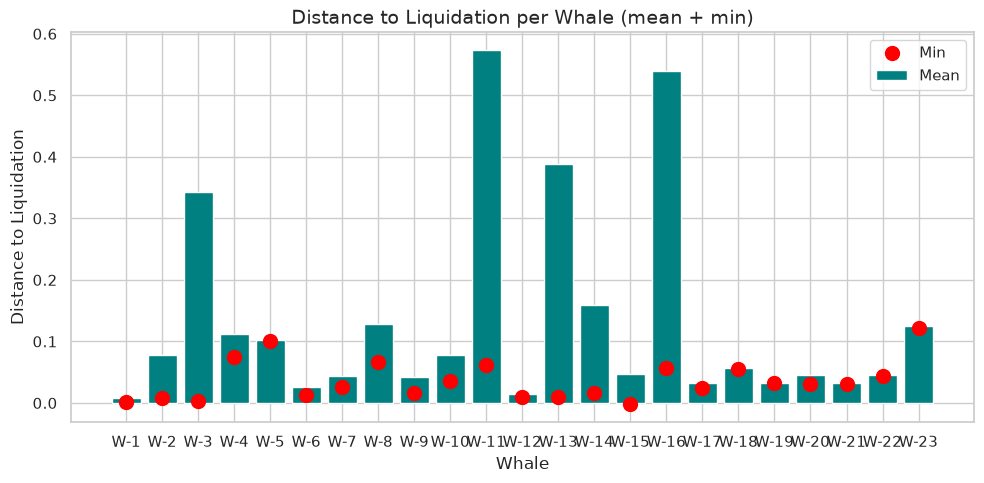

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

summary2 = df.groupby('whale_id')['distance_to_liq'].agg(['mean', 'min'])

whale_order = sorted(summary2.index, key=lambda x: int(x.split('-')[1]))
summary2 = summary2.reindex(whale_order)

ax.bar(summary2.index, summary2['mean'], color='teal', label='Mean')
ax.scatter(summary2.index, summary2['min'], color='red', zorder=5, label='Min', s=100)
ax.set_title('Distance to Liquidation per Whale (mean + min)', fontsize=14)
ax.set_xlabel('Whale')
ax.set_ylabel('Distance to Liquidation')
ax.legend()
plt.tight_layout()
plt.show()

**Distance to Liquidation per Whale (mean + min)**

Each bar shows the average distance to liquidation, how far a whale's position is from being liquidated on a typical day. The red dot marks the closest they ever got to liquidation.

Two whales stand far above the rest. **W-11** and **W-16** have the highest average buffers in the sample, both far above 0.5, meaning they usually sit very safely away from liquidation. Even so, their minimums drop to around 0.06 to 0.08, showing that both whales have had at least one risky moment.

**W-3** and **W-13** show a similar but more extreme pattern. Their average buffers are high (around 0.34 and 0.39), but their minimums fall close to zero. This means both whales swing between long safe periods and sudden brushes with liquidation.

**W-1** sits at the opposite end. Both its mean and minimum are close to zero, meaning it operates with almost no safety buffer at almost all times.

Most other whales form a tight, low cluster, with average buffers under 0.13 and minimums that are often close to zero as well, meaning that even normally cautious whales can have close calls.

Overall, the group splits into three patterns: a small set of whales with very large average buffers but occasional risky dips (W-11, W-16, W-3, W-13), one whale that stays permanently on the edge (W-1), and a large middle group that stays low and fairly steady.

In [6]:
summary3 = df[['whale_id','health_factor','distance_to_liq']].groupby('whale_id').describe().round(4)

whale_order = sorted(summary3.index, key=lambda x: int(x.split('-')[1]))
summary3 = summary3.reindex(whale_order)

summary3


health_factor                                                  \
                 count    mean     std     min     25%     50%     75%   
whale_id                                                                 
W-1               77.0  1.0097  0.0112  1.0016  1.0039  1.0063  1.0102   
W-2              124.0  1.0293  0.0051  1.0080  1.0312  1.0312  1.0315   
W-3               94.0  1.0525  0.0526  1.0036  1.0060  1.0086  1.1137   
W-4               26.0  1.1525  0.1393  1.0883  1.0901  1.0910  1.0917   
W-5               34.0  1.1265  0.0117  1.1227  1.1234  1.1245  1.1257   
W-6               38.0  1.0271  0.0068  1.0144  1.0253  1.0259  1.0342   
W-7               58.0  1.0512  0.0338  1.0301  1.0323  1.0438  1.0470   
W-8               19.0  1.1665  0.0557  1.0788  1.1195  1.1219  1.2223   
W-9               23.0  1.0501  0.0395  1.0177  1.0203  1.0390  1.0626   
W-10             253.0  1.0947  0.0288  1.0414  1.0749  1.0955  1.1043   
W-11             336.0  2.0159  0.9750  1.0780  1.1096  1.7212  3.2781   
W-12              70.0  1.0145  0.0020  1.0110  1.0129  1.0147  1.0159   
W-13              88.0  1.0228  0.0105  1.0104  1.0128  1.0241  1.0259   
W-14             110.0  1.2494  0.3923  1.0174  1.0259  1.0393  1.2884   
W-15               8.0  1.0557  0.0472  0.9978  1.0469  1.0472  1.0475   
W-16              20.0  1.4324  0.5211  1.0672  1.1112  1.2142  1.5377   
W-17              87.0  1.0373  0.0210  1.0269  1.0282  1.0316  1.0346   
W-18              98.0  1.0663  0.0014  1.0645  1.0646  1.0674  1.0675   
W-19               7.0  1.0370  0.0003  1.0367  1.0368  1.0370  1.0373   
W-20              37.0  1.0528  0.0229  1.0348  1.0368  1.0389  1.0863   
W-21               6.0  1.0369  0.0014  1.0350  1.0363  1.0365  1.0380   
W-22               8.0  1.0517  0.0010  1.0503  1.0509  1.0521  1.0526   
W-23              77.0  1.1580  0.0035  1.1538  1.1543  1.1576  1.1616   

                 distance_to_liq                                          \
             max           count    mean     std     min     25%     50%   
whale_id                                                                   
W-1       1.0505            77.0  0.0086  0.0098  0.0014  0.0036  0.0057   
W-2       1.0505           131.0  0.0775  0.2117  0.0076  0.0292  0.0292   
W-3       1.1150           139.0  0.3434  0.4332  0.0035  0.0071  0.0985   
W-4       1.4733            26.0  0.1119  0.0794  0.0743  0.0756  0.0763   
W-5       1.1923            34.0  0.1027  0.0080  0.1000  0.1005  0.1013   
W-6       1.0357            38.0  0.0254  0.0062  0.0137  0.0238  0.0244   
W-7       1.1521            58.0  0.0437  0.0261  0.0267  0.0286  0.0384   
W-8       1.2245            19.0  0.1289  0.0375  0.0669  0.0976  0.0994   
W-9       1.1725            23.0  0.0426  0.0310  0.0159  0.0182  0.0344   
W-10      1.1657           253.0  0.0786  0.0217  0.0364  0.0638  0.0798   
W-11      4.7571           622.0  0.5740  0.3110  0.0622  0.2572  0.6096   
W-12      1.0180            70.0  0.0138  0.0019  0.0105  0.0122  0.0140   
W-13      1.0469           144.0  0.3884  0.4617  0.0099  0.0186  0.0250   
W-14      2.8331           113.0  0.1599  0.2215  0.0165  0.0243  0.0367   
W-15      1.1644             8.0  0.0468  0.0366 -0.0021  0.0410  0.0413   
W-16      2.9390            37.0  0.5403  0.3701  0.0576  0.1459  0.5800   
W-17      1.1122            87.0  0.0328  0.0169  0.0241  0.0252  0.0282   
W-18      1.0676            98.0  0.0572  0.0011  0.0558  0.0558  0.0581   
W-19      1.0375             7.0  0.0329  0.0003  0.0325  0.0327  0.0328   
W-20      1.0911            37.0  0.0458  0.0187  0.0309  0.0326  0.0345   
W-21      1.0385             6.0  0.0327  0.0012  0.0311  0.0322  0.0324   
W-22      1.0526             8.0  0.0452  0.0008  0.0441  0.0446  0.0455   
W-23      1.1638            77.0  0.1255  0.0024  0.1226  0.1230  0.1252   

                          
             75%     max  
whale_id                  
W-1       0.0092  0.0440  

**Health Factor & Distance to Liquidation Summary Statistics**

This table shows the full distribution of both risk metrics per whale across the sample period.

---

**Health Factor:**

Most whales sit in a normal, safe range, with mean health factor between about 1.01 and 1.17, and fairly small standard deviations.

A few whales stand apart:

- **W-11** is the extreme outlier. Mean health factor is 2.02, with a very high standard deviation of 0.975 and a max of 4.76. This whale sometimes runs at a very safe level and sometimes spikes much higher.
- **W-16** and **W-14** are also elevated, with means of 1.43 and 1.25, and both have high maximums (2.94 and 2.83), showing occasional large jumps above their normal range.
- **W-3** stands out for its spread rather than its average. Mean is 1.053, but values range from 1.004 to 1.115, showing two different modes of operation, sometimes close to liquidation and sometimes safer.

On the low risk end:

- **W-4**, **W-5**, **W-8**, and **W-24** keep the highest average health factors, generally above 1.15, meaning they always keep a solid buffer.
- **W-1** and **W-12** sit at the other extreme, with very low and tightly packed values close to 1.01, meaning they operate with almost no safety margin at any point.

---

**Distance to Liquidation:**

The same overall pattern shows up here.

- **W-11** and **W-16** have by far the highest average buffers, 0.574 and 0.540, but their minimums (0.062 and 0.058) show they still had risky moments.
- **W-3** and **W-13** show a similar high mean but low minimum pattern, with means around 0.343 and 0.388, but minimums near zero (0.0035 and 0.0099). This confirms these whales swing between very safe and very risky periods, matching what we see in their health factor numbers.
- **W-1** has both a very low mean (0.009) and a very low max (0.044), confirming it is almost always close to liquidation.
- **W-4**, **W-5**, and **W-24** have the steadiest, safest profiles, with tight ranges and minimums that never drop close to zero.

One thing worth checking: **W-11** has 622 rows for distance to liquidation but only 336 for health factor. This gap is much bigger than for other whales, so it may be worth checking if some health factor values are missing or filtered out for this whale.

---

Across both metrics, the whales split into three main groups. **W-11**, **W-16**, **W-3**, and **W-13** show high averages but also high volatility, meaning strong safety most of the time but occasional close calls. **W-4**, **W-5**, **W-8**, and **W-24** are the steady, conservative operators. **W-1** and **W-12** are the two whales that consistently sit close to liquidation with almost no buffer.

In [7]:
# Each whale is stressed when health factor drops to 1.05 or below (same rule for all whales)
STRESS_THRESHOLD = 1.05

df['stressed_state'] = (df['health_factor'] <= STRESS_THRESHOLD).astype(int)

stressed_rate = df.groupby('whale_id')['stressed_state'].mean().round(3)

whale_order = sorted(stressed_rate.index, key=lambda x: int(x.split('-')[1]))
stressed_rate = stressed_rate.reindex(whale_order)

print('Stressed rate per whale:')
print(stressed_rate)
print(f'\nOverall stressed rate: {df["stressed_state"].mean():.1%}')

Stressed rate per whale:
whale_id
W-1     0.962
W-2     0.410
W-3     0.381
W-4     0.000
W-5     0.000
W-6     0.528
W-7     0.810
W-8     0.000
W-9     0.708
W-10    0.043
W-11    0.000
W-12    0.986
W-13    0.564
W-14    0.653
W-15    0.778
W-16    0.000
W-17    0.909
W-18    0.000
W-19    0.143
W-20    0.222
W-21    0.133
W-22    0.000
W-23    0.000
Name: stressed_state, dtype: float64

Overall stressed rate: 28.9%


In [8]:
summary = df.groupby('whale_id').agg(
    mean_hf=('health_factor', 'mean'),
    min_hf=('health_factor', 'min'),
    max_hf=('health_factor', 'max'),
    stressed_pct=('stressed_state', 'mean')
).round(3)

summary['stressed_pct'] = (summary['stressed_pct'] * 100).round(1).astype(str) + '%'

whale_order = sorted(summary.index, key=lambda x: int(x.split('-')[1]))
summary = summary.reindex(whale_order)

print('Health Factor Summary per Whale:')
print(summary.to_string())

Health Factor Summary per Whale:
          mean_hf  min_hf  max_hf stressed_pct
whale_id                                      
W-1         1.010   1.002   1.051        96.2%
W-2         1.029   1.008   1.051        41.0%
W-3         1.052   1.004   1.115        38.1%
W-4         1.153   1.088   1.473         0.0%
W-5         1.127   1.123   1.192         0.0%
W-6         1.027   1.014   1.036        52.8%
W-7         1.051   1.030   1.152        81.0%
W-8         1.166   1.079   1.225         0.0%
W-9         1.050   1.018   1.173        70.8%
W-10        1.095   1.041   1.166         4.3%
W-11        2.016   1.078   4.757         0.0%
W-12        1.015   1.011   1.018        98.6%
W-13        1.023   1.010   1.047        56.4%
W-14        1.249   1.017   2.833        65.3%
W-15        1.056   0.998   1.164        77.8%
W-16        1.432   1.067   2.939         0.0%
W-17        1.037   1.027   1.112        90.9%
W-18        1.066   1.065   1.068         0.0%
W-19        1.037   1.037  

**Stressed Rate per Whale (fixed threshold method)**

A whale is marked stressed on any day its health factor drops to 1.05 or below. This number means the same thing for every whale, so the results below show real risk, not just "worse than usual for that whale."

**Almost always stressed (above 80%):**
W-12 and W-1 are the riskiest whales in the group, stressed 98.6% and 96.2% of the time. Both keep a mean health factor close to 1.01 to 1.02, so they sit right next to liquidation almost every single day. W-18 is close behind at 90.9%, and W-7 sits at 81.0%.

**Often stressed (40% to 80%):**
W-9, W-15, W-14, W-13, and W-6 fall in this range, with stressed rates between 52.8% and 70.8%. W-9 is a good example of why the mean alone can be misleading. Its mean health factor is 1.050, which looks fine at first glance, but it is still stressed 70.8% of the time, meaning it spends most days hovering near the danger line with only occasional safer moments pulling the average up.

**Occasionally stressed (under 45%):**
W-2, W-3, W-21, W-20, and W-22 sit in this lower range, from about 13% to 41%. These whales spend most of their time safely above the threshold, with only some days dipping close to danger.

**Never stressed (0%):**
W-4, W-5, W-8, W-11, W-16, W-17, W-19, W-23, and W-24 never dropped to 1.05 or below. These whales keep a safe distance from liquidation at all times. This group includes both steady, low mean whales like W-19, and whales with very high means and big swings like W-11 and W-16, showing that a high average alone does not guarantee safety, but in these cases it lined up with staying safe.

Overall, the fixed threshold method gives a clearer picture of real danger. It shows that risk is not evenly spread across whales. A small group, led by W-1 and W-12, spends nearly all its time in a dangerous zone, while another group almost never gets close to liquidation at all.

In [9]:
print('Rebalancing distribution:')
print(df['rebalancing'].value_counts())
print(f'\nRebalancing rate: {df["rebalancing"].mean():.1%}')
print('\nRebalancing days per whale:')

rebal_summary = df.groupby('whale_id')['rebalancing'].agg(
    total_days='count',
    rebal_days='sum',
    rebal_pct=lambda x: f'{x.mean():.1%}'
)

whale_order = sorted(rebal_summary.index, key=lambda x: int(x.split('-')[1]))
rebal_summary = rebal_summary.reindex(whale_order)

rebal_summary

Rebalancing distribution:
rebalancing
0    2136
1     370
Name: count, dtype: int64

Rebalancing rate: 14.8%

Rebalancing days per whale:


,total_days,rebal_days,rebal_pct
whale_id,,,
W-1,78,15,19.2%
W-2,300,11,3.7%
W-3,139,66,47.5%
W-4,27,5,18.5%
W-5,35,4,11.4%
W-6,72,7,9.7%
W-7,58,26,44.8%
W-8,20,4,20.0%
W-9,24,7,29.2%


Overall, whales rebalanced on 371 out of 2,507 days, which is 14.8% of the time.

Most active rebalancers (above 40%):
W-15 and W-23 rebalance most often, both at 55.6%. W-16 is close behind at 52.6%, and W-3 rebalances 47.5% of the time. W-7 also rebalances often, at 44.8%. These whales adjust their position very frequently, often several times a week.

Moderately active (about 15% to 30%):
W-9, W-14, W-22, and W-1 fall in this range, from 19.2% up to 29.2%. These whales rebalance from time to time, but not as often as the top group.

Low activity (under 15%):
Most other whales sit in this range, including W-11, W-4, W-13, W-8, W-5, W-20, W-6, W-21, W-18, W-19, W-24, W-2, W-10, and W-12. Their rebalancing rates go from about 1.6% up to 12.2%. These whales mostly hold their position and only rarely make adjustments.

Special case:
W-17 shows 100%, but this is because it only has one row of data, so its single day counts as 100%. This number should be treated carefully since one day is not enough to say anything meaningful about this whale's habits.

Key takeaway: W-15, W-23, W-16, W-3, and W-7 are the most active risk managers, adjusting their position often. Most other whales are far more passive, with several rebalancing on fewer than 1 in 10 days.

In [10]:
df.to_csv('whale_features_labeled.csv', index=False)
print('Saved: whale_features_labeled.csv')
print(f'Final shape: {df.shape}')
print(f'\nColumns added: stressed_state')

Saved: whale_features_labeled.csv
Final shape: (2506, 39)

Columns added: stressed_state
